# Proyecto completo de Machine Learning: precio del gasóleo en las gasolineras de España

## 1. Obtención de datos

**Fuente:** Ministerio para la Transición Ecológica y el Reto Demográfico (MITECO),
servicio REST de precios de carburantes en estaciones de servicio terrestres.

**Cómo se obtienen los datos originalmente:** por ley, todas las estaciones de servicio de España
están obligadas a comunicar al Ministerio los precios de venta al público de sus carburantes.
Los envían ellas mismas o a través de su operador mayorista (la petrolera que les suministra).
El Ministerio publica esos precios en tiempo real.

**Cómo los he obtenido yo:** el servidor del Ministerio rechaza las conexiones desde Google Colab,
así que descargué los datos con un script de Python en mi ordenador y los guardé en un CSV.

**Fecha de los datos:** 9 de noviembre de 2026, 9:42 h. Son una "foto" de los precios en ese momento.

In [12]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

gasolineras = pd.read_csv("/content/drive/MyDrive/IA & Big Data/IA/gasolineras_2026-11-09.csv")
gasolineras.shape

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(11479, 41)

In [13]:
for columna in ["Margen", "Remisión", "Tipo Venta"]:
    print(gasolineras[columna].value_counts(), "\n")

Margen
D    6094
I    2724
N    2661
Name: count, dtype: int64 

Remisión
dm    7446
OM    4033
Name: count, dtype: int64 

Tipo Venta
P    11479
Name: count, dtype: int64 



## 2. Descripción de los datos

El dataset tiene **11.479 filas** (una por gasolinera) y **41 columnas**. Estas son las que voy a usar:

| Columna | Significado |
|---|---|
| `Precio Gasoleo A` | Precio del gasóleo normal en €/litro. **Es el valor a predecir (target).** |
| `Latitud`, `Longitud (WGS84)` | Coordenadas de la gasolinera. |
| `Provincia` | Provincia en la que está. |
| `Municipio`, `Localidad` | Municipio y localidad. |
| `Rótulo` | Marca o nombre del cartel (REPSOL, CEPSA, PLENOIL...). Si la gasolinera no tiene marca, aparece su número de registro (por ejemplo, "Nº 10.935"). |
| `Horario` | Horario de apertura, en texto (por ejemplo, "L-D: 24H"). |
| `Margen` | Lado de la carretera: D = derecho, I = izquierdo, N = no aplicable. |
| `Remisión` | Quién comunica los precios al Ministerio. Interpretación: dm = la propia gasolinera, OM = su operador mayorista. |

**Columnas que no voy a usar:**

* **Los demás precios** (gasolina 95, 98, AdBlue, hidrógeno, etc.). Usar el precio de otros carburantes para predecir el del gasóleo sería hacer trampa: en la práctica dependen de los mismos factores y casi lo "chivan". Además, muchas gasolineras no venden la mayoría de ellos (tienen valores nulos).
* **`Tipo Venta`**: todas las filas tienen el valor P (venta al público), así que no aporta información.
* **`IDEESS`, `IDMunicipio`, `IDProvincia`, `IDCCAA`, `C.P.`, `Dirección`**: son identificadores y direcciones. No sirven para predecir, o repiten información que ya está en otras columnas.
* **`% BioEtanol`, `% Éster metílico`**: porcentajes de biocombustible en las mezclas. En el caso del éster metílico, solo 29 gasolineras tienen un valor distinto de 0, así que no aporta información.

## 3. Exploración y visualización de los datos

In [14]:
# info() muestra, para cada columna:
#   - cuántos valores NO nulos tiene (si hay menos de 11479, el resto son nulos)
#   - de qué tipo es: float64 = número decimal, int64 = número entero, object = texto
gasolineras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11479 entries, 0 to 11478
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   C.P.                                11479 non-null  int64  
 1   Dirección                           11479 non-null  object 
 2   Horario                             11479 non-null  object 
 3   Latitud                             11479 non-null  object 
 4   Localidad                           11479 non-null  object 
 5   Longitud (WGS84)                    11479 non-null  object 
 6   Margen                              11479 non-null  object 
 7   Municipio                           11479 non-null  object 
 8   Precio Adblue                       2946 non-null   object 
 9   Precio Amoniaco                     0 non-null      float64
 10  Precio Biodiesel                    29 non-null     object 
 11  Precio Bioetanol                    1 non

Los precios y las coordenadas aparecen como texto (`object`) en vez de como números,
porque vienen con coma decimal ("1,459") y Python usa el punto. Hay que convertirlos.

Además, renombro las dos columnas que más voy a usar para que sean más cómodas de escribir.

In [15]:
# --- 1. Lista de columnas que deberían ser números pero vienen como texto ---

# List comprehension: recorre todas las columnas y se queda con las que empiezan por "Precio"
columnas_numericas = [c for c in gasolineras.columns if c.startswith("Precio")]

# Añadimos a la lista las coordenadas y los dos porcentajes, que también vienen con coma
columnas_numericas += ["Latitud", "Longitud (WGS84)", "% BioEtanol", "% Éster metílico"]


# --- 2. Convertimos cada columna de texto a número ---

for columna in columnas_numericas:
    gasolineras[columna] = pd.to_numeric(
        gasolineras[columna]
            .astype(str)                              # tratamos la columna como texto
            .str.replace(",", ".", regex=False),      # cambiamos la coma decimal por punto: "1,459" -> "1.459"
        errors="coerce"                               # si algún valor no se puede convertir, lo deja como nulo (NaN) en vez de dar error
    )


# --- 3. Renombramos las dos columnas que más vamos a usar, para escribirlas más fácil ---

gasolineras = gasolineras.rename(columns={
    "Precio Gasoleo A": "precio_gasoleo_a",
    "Longitud (WGS84)": "Longitud"
})


# --- 4. Comprobación: estas tres columnas ya deberían salir como float64 ---

gasolineras[["precio_gasoleo_a", "Latitud", "Longitud"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11479 entries, 0 to 11478
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   precio_gasoleo_a  11261 non-null  float64
 1   Latitud           11479 non-null  float64
 2   Longitud          11479 non-null  float64
dtypes: float64(3)
memory usage: 269.2 KB


In [16]:
# isnull() marca con True los valores nulos; sum() cuenta cuántos True hay
# -> número de gasolineras que NO venden gasóleo A (debería salir 218)
print("Gasolineras sin precio de gasóleo A:", gasolineras["precio_gasoleo_a"].isnull().sum())

# != 0 marca con True las filas cuyo valor no es 0; sum() las cuenta
# -> comprobamos si la columna "% Éster metílico" tiene información o es todo ceros
print("Gasolineras con % Éster metílico distinto de 0:", (gasolineras["% Éster metílico"] != 0).sum())

# describe() da las estadísticas básicas del precio:
#   count = nº de valores, mean = media, std = desviación típica (cuánto se separan de la media),
#   min / max = mínimo y máximo, 25% / 50% / 75% = cuartiles (el 50% es la mediana)
gasolineras["precio_gasoleo_a"].describe()

Gasolineras sin precio de gasóleo A: 218
Gasolineras con % Éster metílico distinto de 0: 29


,precio_gasoleo_a
count,11261.000000
mean,1.869379
std,0.100835
min,1.381000
25%,1.787000
50%,1.899000
75%,1.950000
max,2.249000


**Observaciones:**

* 218 gasolineras no tienen precio de gasóleo A (no lo venden). Habrá que eliminarlas, porque no se puede entrenar con filas que no tienen el valor a predecir.
* La columna `% Éster metílico` solo tiene un valor distinto de 0 en 29 gasolineras, así que no aporta información.
* El precio medio del gasóleo A es de 1,869 €/litro y la mediana de 1,899 €/litro.
* El 50 % central de las gasolineras está entre 1,787 y 1,950 €/litro: los precios están bastante concentrados (desviación típica de 0,10 €).
* El mínimo, 1,381 €/litro, está muy alejado del resto. La media es menor que la mediana porque hay un grupo pequeño de gasolineras mucho más baratas. Mi hipótesis es que son las de Canarias, Ceuta y Melilla, que tienen menos impuestos sobre los carburantes. Lo compruebo más adelante.

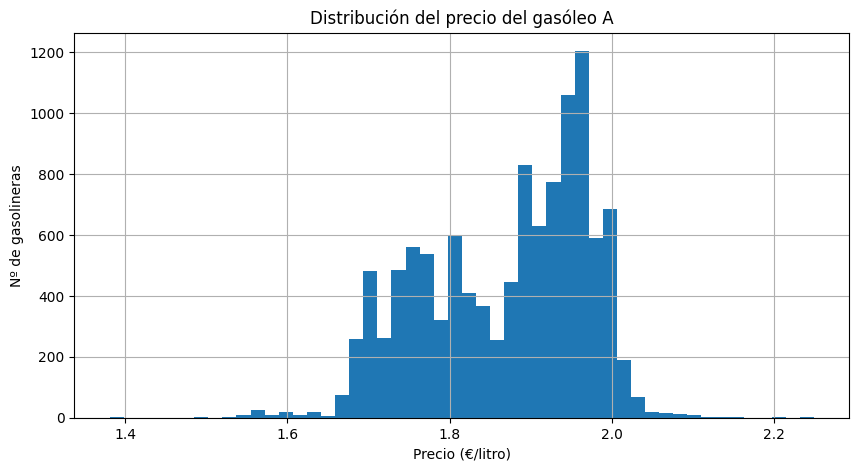

In [17]:
# Histograma: divide el rango de precios en 50 franjas (bins)
# y dibuja una barra con cuántas gasolineras hay en cada franja
gasolineras["precio_gasoleo_a"].hist(bins=50, figsize=(10, 5))   # figsize = tamaño del gráfico (ancho, alto)

plt.title("Distribución del precio del gasóleo A")   # título del gráfico
plt.xlabel("Precio (€/litro)")                       # texto del eje horizontal
plt.ylabel("Nº de gasolineras")                      # texto del eje vertical
plt.show()                                           # muestra el gráfico

**Observaciones del histograma:**

* La distribución tiene **dos picos**: un grupo de gasolineras entre 1,70 y 1,80 €/litro y otro grupo más numeroso entre 1,90 y 2,00 €/litro. Esto sugiere que hay dos tipos de gasolineras con políticas de precio diferentes. Mi hipótesis es que el grupo barato corresponde a gasolineras de bajo coste o independientes y el caro a las grandes marcas. Lo compruebo más adelante con la columna `Rótulo`.
* Hay una cola de pocas gasolineras muy baratas, entre 1,40 y 1,65 €/litro, separada del resto. Encaja con la hipótesis de Canarias, Ceuta y Melilla.
* También hay unas pocas gasolineras caras por encima de 2,05 €/litro, hasta un máximo de 2,25.